# Figuras do relatório (MAC0214)

Com `PAPER_MODE = True`, cada figura é salva em PDF vetorial em `../figures/<nome>.pdf`.

Entradas esperadas em `dataset/`:

| arquivo                  | obrigatório | usado em                         |
|--------------------------|-------------|----------------------------------|
| `executions.parquet`     | sim         | sucesso, cache                   |
| `repositories.parquet`   | sim         | tempos, aceleração, similaridade |

In [70]:
import math
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, MaxNLocator, NullLocator

DATA_DIR = Path("dataset")
FIG_DIR = Path("figures")

PAPER_MODE = True

# No LaTeX, rode \showthe\textwidth e divida o valor em pt por 72.27.
# Para article, a4paper, 10pt e margens padrão: 345pt = 4.77in.
TEXT_WIDTH_IN = 345 / 72.27

REFERENCE_SIMILARITY = 1.0

VERSION_LABELS = {"v0.7.0": "v0.7.0-rc"}

In [71]:
COLORS = {
    "ok": "#2ECC71",
    "fail": "#E74C3C",
    "flaky": "#F39C12",
    "gray": "#9AA0A6",
    "text": "#333333",
}
VERSION_COLORS = {"v0.5.1": "#5A9A8F", "v0.7.0": "#2C6478"}
_EXTRA = ["#8E6C8A", "#B5651D", "#4F6D7A", "#A3A847"]

VERSION_MARKERS = ["o", "s", "^", "D", "v", "X"]
VERSION_HATCHES = ["", "//", "xx", "..", "++", "oo"]


def apply_style(paper=False):
    if not paper:
        sns.set_theme(style="whitegrid", context="notebook")
        plt.rcParams.update({
            "figure.dpi": 110,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.titlesize": 13,
            "axes.titleweight": "bold",
            "legend.frameon": False,
        })
        return

    sns.set_theme(style="white")
    plt.rcParams.update({
        "text.usetex": True,
        "text.latex.preamble": r"\usepackage[T1]{fontenc}\usepackage[utf8]{inputenc}",
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman", "Latin Modern Roman", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        "font.size": 10,
        "axes.labelsize": 10,
        "axes.titlesize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.title_fontsize": 9,
        "pdf.fonttype": 42,
        "savefig.dpi": 300,
        "figure.dpi": 150,
        "axes.linewidth": 0.6,
        "axes.edgecolor": COLORS["text"],
        "axes.labelcolor": COLORS["text"],
        "xtick.color": COLORS["text"],
        "ytick.color": COLORS["text"],
        "lines.linewidth": 1.4,
        "lines.markersize": 4,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#E5E5E5",
        "grid.linewidth": 0.5,
        "legend.frameon": False,
        "axes.unicode_minus": False,
    })


apply_style(PAPER_MODE)

In [72]:
def fig_size(h_ratio, w_frac=1.0):
    w = TEXT_WIDTH_IN * w_frac if PAPER_MODE else 10 * w_frac
    return (w, w * h_ratio)


def set_title(target, text, **kw):
    if not PAPER_MODE:
        (target.set_title if hasattr(target, "set_title") else target.suptitle)(text, **kw)


def tex(s):
    s = str(s)
    if plt.rcParams["text.usetex"]:
        for ch in "%&_#":
            s = s.replace(ch, "\\" + ch)
    return s


TIMES = r"$\times$"


def save_fig(fig, name):
    if PAPER_MODE:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", pad_inches=0.02)
        print(f"salvo: {FIG_DIR / (name + '.pdf')}")


def br(x, nd=1):
    s = f"{x:,.{nd}f}"
    return s.replace(",", "\0").replace(".", ",").replace("\0", ".")


def br_trim(x, nd=1):
    s = br(x, nd)
    return s.rstrip("0").rstrip(",") if "," in s else s


def fmt_seconds(s):
    if pd.isna(s):
        return ""
    if s < 60:
        return f"{br_trim(s)}s"
    if s < 3600:
        return f"{br_trim(s / 60)}min"
    if s < 86400:
        return f"{br_trim(s / 3600)}h"
    return f"{br_trim(s / 86400)}d"


def fmt_duration(s):
    if pd.isna(s):
        return ""
    if s < 10:
        return f"{br(s)}s"
    d, rem = divmod(int(round(s)), 86400)
    h, rem = divmod(rem, 3600)
    m, sec = divmod(rem, 60)
    if d:
        return f"{d}d {h}h"
    if h:
        return f"{h}h {m:02d}min"
    if m:
        return f"{m}min {sec:02d}s"
    return f"{sec}s"


def time_ticks(values):
    lo, hi = values.min(), values.max()
    candidates = [0.1, 1, 10, 60, 600, 3600, 36000, 86400, 864000]
    return [c for c in candidates if lo * 0.5 <= c <= hi * 1.5]


def vlabel(v):
    return tex(VERSION_LABELS.get(v, v))


def vcolor(v, i=0):
    return VERSION_COLORS.get(v, _EXTRA[i % len(_EXTRA)])


def sim_label(s):
    return br(s, 2)

## Dados

In [73]:
executions = pd.read_parquet(DATA_DIR / "executions.parquet")
repositories = pd.read_parquet(DATA_DIR / "repositories.parquet")

executions_ref = executions[executions["similarity"] == REFERENCE_SIMILARITY]
repositories_ref = repositories[repositories["similarity"] == REFERENCE_SIMILARITY]
ok_ref = repositories_ref[repositories_ref["status"] == "success"].copy()

versions = sorted(executions_ref["tool_version"].unique())
versions_all = sorted(executions["tool_version"].dropna().unique())
sim_values = sorted(repositories["similarity"].dropna().unique())
palette = {v: vcolor(v, i) for i, v in enumerate(versions_all)}

print(executions[[
    "run_id", "tool_version", "similarity", "total", "success", "failed", "total_duration_seconds"
]].to_string(index=False))
print()
print(repositories.groupby(["tool_version", "similarity", "status"]).size())

               run_id tool_version  similarity  total  success  failed  total_duration_seconds
v0.5.1-sim0.80-run001       v0.5.1         0.8      7        5       2           358393.386873
v0.5.1-sim1.00-run001       v0.5.1         1.0      7        5       2           352128.343859
v0.7.0-sim0.80-run001       v0.7.0         0.8      7        6       1            31135.981604
v0.7.0-sim1.00-run001       v0.7.0         1.0      7        6       1             2809.593452

tool_version  similarity  status 
v0.5.1        0.8         failed     2
                          success    5
              1.0         failed     2
                          success    5
v0.7.0        0.8         failed     1
                          success    6
              1.0         failed     1
                          success    6
dtype: int64


## Sucessos e falhas por versão (`outcomes_by_version`)

salvo: figures/outcomes_by_version.pdf


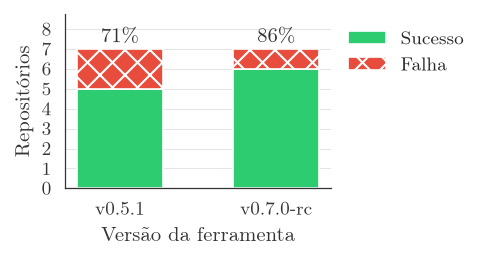

In [74]:
runs_per_version = executions_ref.groupby("tool_version")["run_id"].nunique().reindex(versions)
multi_run = runs_per_version.max() > 1

per_repo = (repositories_ref
    .assign(is_success=repositories_ref["status"] == "success")
    .groupby(["tool_version", "repository"])["is_success"]
    .agg(n_success="sum", n_runs="count"))
per_repo["outcome"] = np.select(
    [per_repo["n_success"] == per_repo["n_runs"], per_repo["n_success"] == 0],
    ["ok", "fail"], default="flaky",
)
cols = ["ok", "flaky", "fail"]
totals = (per_repo
    .groupby(["tool_version", "outcome"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=versions, columns=cols, fill_value=0))
totals["total"] = totals[cols].sum(axis=1)
success_rate = executions_ref.groupby("tool_version")["success_rate"].mean().reindex(versions)

fig, ax = plt.subplots(figsize=fig_size(0.55, 0.7))
bottom = np.zeros(len(versions))
names = {"ok": "Sucesso", "flaky": "Intermitente", "fail": "Falha"}
for col, hatch in zip(cols, ["", "//", "xx"]):
    vals = totals[col].to_numpy()
    if vals.sum() == 0:
        continue
    bars = ax.bar(
        range(len(versions)),
        vals,
        bottom=bottom,
        width=0.55,
        color=COLORS[col],
        edgecolor="white",
        linewidth=0.8,
        hatch=hatch if PAPER_MODE else None,
        label=names[col]
    )
    bottom += vals

for i, v in enumerate(versions):
    ax.text(
        i,
        totals.loc[v, "total"] + 0.15,
        tex(f"{success_rate[v]:.0%}"),
        ha="center",
        va="bottom",
        fontweight="bold",
        color=COLORS["text"]
    )

ax.set_xticks(range(len(versions)))
ax.set_xticklabels([
    vlabel(v) + (f"\n(n={runs_per_version[v]})" if multi_run else "") for v in versions
])
ax.set_ylim(0, totals["total"].max() * 1.25)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Versão da ferramenta")
ax.set_ylabel("Repositórios")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
set_title(ax, "Sucessos e falhas por versão", loc="left")
fig.tight_layout()
save_fig(fig, "outcomes_by_version")
plt.show()

## Tempo por repositório e versão (`time_by_repository`)

salvo: figures/time_by_repository.pdf


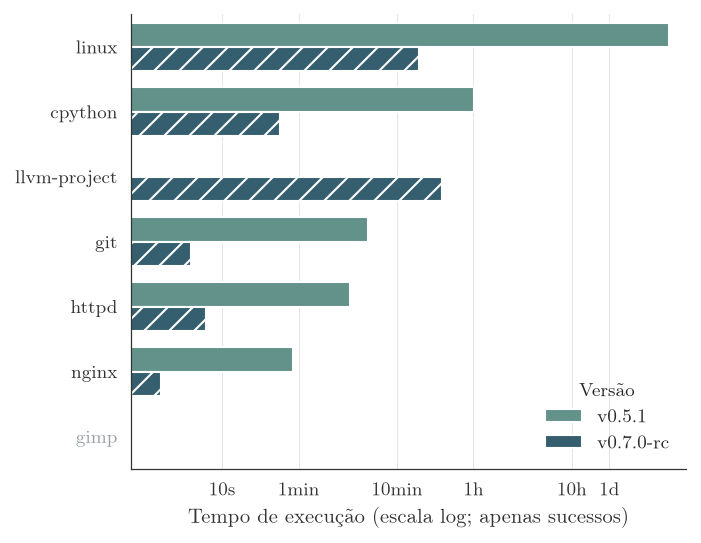

In [75]:
succeeded = (ok_ref
    .groupby("repository")["duration_seconds"]
    .median()
    .sort_values(ascending=False).index.tolist())
failed_everywhere = sorted(set(repositories_ref["repository"]) - set(succeeded))
repository_order = succeeded + failed_everywhere
flaky_repos = set(per_repo.index[per_repo["outcome"] == "flaky"].get_level_values("repository"))

fig, ax = plt.subplots(figsize=fig_size(min(0.045 * len(repository_order) * len(versions) + 0.15, 0.9)))
sns.barplot(
    data=ok_ref,
    y="repository",
    x="duration_seconds",
    hue="tool_version",
    hue_order=versions,
    order=repository_order,
    palette=palette,
    orient="h",
    width=0.75,
    errorbar=("pi", 100) if multi_run else None,
    capsize=0.2,
    err_kws={"linewidth": 0.8, "color": COLORS["text"]},
    ax=ax,
)
if PAPER_MODE:
    for container, hatch in zip(ax.containers, VERSION_HATCHES):
        for patch in container.patches:
            patch.set_hatch(hatch)

ax.set_xscale("log")
ticks = time_ticks(ok_ref["duration_seconds"])
ax.set_xticks(ticks)
ax.set_xticklabels([fmt_seconds(t) for t in ticks])
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xlim(ok_ref["duration_seconds"].min() * 0.5, ok_ref["duration_seconds"].max() * 1.5)
ax.grid(axis="x", color="#E5E5E5", linewidth=0.5)
ax.grid(axis="y", visible=False)

ax.set_yticks(range(len(repository_order)))
ax.set_yticklabels([tex(r) + ("*" if r in flaky_repos else "") for r in repository_order])
for label in ax.get_yticklabels():
    if label.get_text().rstrip("*") in failed_everywhere:
        label.set_color(COLORS["gray"])
        label.set_style("italic")

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [vlabel(l) for l in labels], title="Versão", loc="lower right")
ax.set_xlabel("Tempo de execução (escala log; apenas sucessos)")
ax.set_ylabel("")
set_title(ax, "Tempo de execução por repositório e versão", loc="left")
fig.tight_layout()
save_fig(fig, "time_by_repository")
plt.show()

## Aceleração em função do tamanho (`speedup_by_size`)

salvo: figures/speedup_by_size.pdf


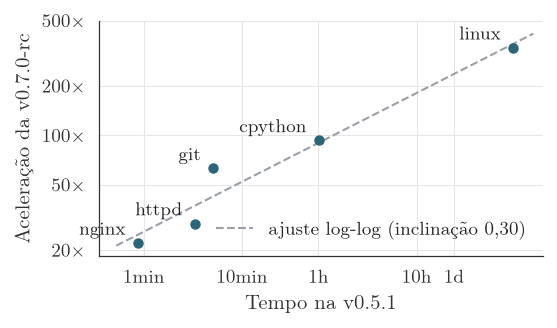

inclinação do ajuste: 0.304
tool_version         v0.5.1       v0.7.0  speedup
repository                                       
nginx             52.604621     2.375758     22.1
httpd            198.397662     6.830074     29.0
git              307.197392     4.879144     63.0
cpython         3651.486466    39.178683     93.2
linux         347918.657718  1017.088116    342.1


In [76]:
old_v, new_v = versions[0], versions[-1]
med = ok_ref.groupby(["tool_version", "repository"])["duration_seconds"].median().unstack(0)
speed = med[[old_v, new_v]].dropna()
speed["speedup"] = speed[old_v] / speed[new_v]
speed = speed.sort_values(old_v)

slope, intercept = np.polyfit(np.log10(speed[old_v]), np.log10(speed["speedup"]), 1)

fig, ax = plt.subplots(figsize=fig_size(0.6, 0.8))
ax.scatter(speed[old_v], speed["speedup"], color=vcolor(new_v), zorder=3)
for repo, row in speed.iterrows():
    ax.annotate(
        tex(repo),
        (row[old_v],row["speedup"]),
        xytext=(-6, 4),
        textcoords="offset points",
        ha="right",
        fontsize=9
    )
xs = np.logspace(np.log10(speed[old_v].min() * 0.6), np.log10(speed[old_v].max() * 1.6), 50)
ax.plot(
    xs,
    10 ** intercept * xs ** slope,
    linestyle="--",
    color=COLORS["gray"],
    linewidth=1,
    label=tex(f"ajuste log-log (inclinação {br(slope, 2)})")
)
ax.set_xscale("log")
ax.set_yscale("log")
ticks = time_ticks(speed[old_v])
ax.set_xticks(ticks)
ax.set_xticklabels([fmt_seconds(t) for t in ticks])
ax.xaxis.set_minor_locator(NullLocator())
yt = [
    t for t in [10, 20, 50, 100, 200, 500, 1000]
    if speed["speedup"].min() * 0.6 <= t <= speed["speedup"].max() * 1.6
]
ax.set_yticks(yt)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}" + TIMES))
ax.yaxis.set_minor_locator(NullLocator())
ax.set_xlim(speed[old_v].min() * 0.4, speed[old_v].max() * 2.0)
ax.grid(axis="x", color="#E5E5E5", linewidth=0.5)
ax.set_xlabel(f"Tempo na {vlabel(old_v)}")
ax.set_ylabel(f"Aceleração da {vlabel(new_v)}")
ax.legend(loc="lower right")
set_title(ax, "Aceleração por tamanho do repositório", loc="left")
fig.tight_layout()
save_fig(fig, "speedup_by_size")
plt.show()

print(f"inclinação do ajuste: {slope:.3f}")
print(speed.assign(speedup=speed["speedup"].round(1)).to_string())

## Mapa de calor por repositório (`similarity_heatmap`)

salvo: figures/similarity_heatmap.pdf


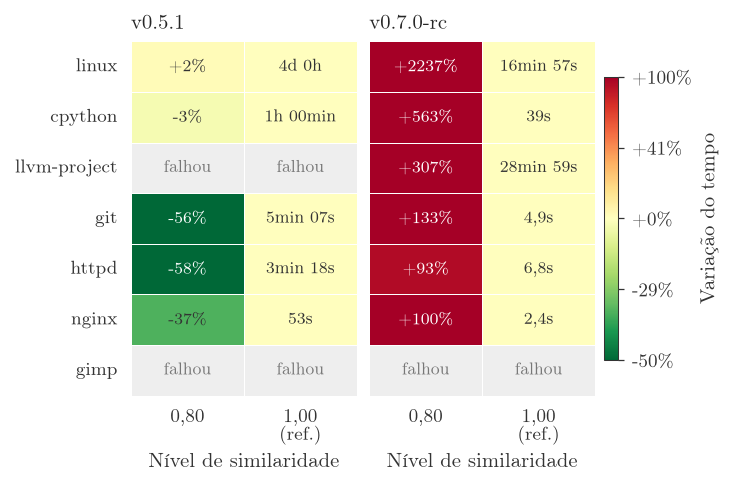

In [77]:
successful = repositories[repositories["status"].eq("success")]
repo_times = (successful
    .groupby(["tool_version", "similarity", "repository"])["duration_seconds"]
    .median()
    .rename("seconds")
    .reset_index())
baseline = repo_times[repo_times["similarity"].eq(REFERENCE_SIMILARITY)]

ncols = min(2, len(versions_all))
nrows = math.ceil(len(versions_all) / ncols)

order = (baseline
    .groupby("repository")["seconds"]
    .median()
    .sort_values(ascending=False).index.tolist())
order += sorted(set(repositories["repository"]) - set(order))
failed_cells = set(map(tuple, repositories.loc[
    repositories["status"].eq("failed"), ["tool_version", "repository", "similarity"]
].to_numpy()))
lookup = repo_times.set_index(["tool_version", "repository", "similarity"])["seconds"]
LIM = 1.0

fig, axes = plt.subplots(
    nrows, ncols, squeeze=False, constrained_layout=True,
    figsize=fig_size(min(0.065 * len(order) + 0.2, 2.0) * nrows))
for ax in axes.flat[len(versions_all):]:
    ax.axis("off")

xlabels = [sim_label(s) + ("\n(ref.)" if s == REFERENCE_SIMILARITY else "") for s in sim_values]
for idx, v in enumerate(versions_all):
    ax = axes.flat[idx]
    matrix = pd.DataFrame(np.nan, index=order, columns=sim_values, dtype=float)
    notes = {}
    for repo in order:
        base_t = lookup.get((v, repo, REFERENCE_SIMILARITY), np.nan)
        for s in sim_values:
            t = lookup.get((v, repo, s), np.nan)
            if pd.notna(t) and pd.notna(base_t) and base_t > 0:
                matrix.loc[repo, s] = np.log2(t / base_t)
                notes[(repo, s)] = (fmt_duration(t) if s == REFERENCE_SIMILARITY
                                    else tex(f"{(t / base_t - 1) * 100:+.0f}%"))
            elif pd.notna(t):
                notes[(repo, s)] = fmt_duration(t)
            elif (v, repo, s) in failed_cells:
                notes[(repo, s)] = "falhou"

    sns.heatmap(
        matrix,
        ax=ax,
        cmap="RdYlGn_r",
        vmin=-LIM,
        vmax=LIM,
        center=0,
        cbar=False,
        linewidths=0.4,
        linecolor="white",
        mask=matrix.isna(),
        xticklabels=xlabels,
        yticklabels=(idx % ncols == 0)
    )
    ax.set_facecolor("#EEEEEE")
    ax.grid(False)
    for r_i, repo in enumerate(order):
        for c_i, s in enumerate(sim_values):
            lab = notes.get((repo, s))
            if lab is None:
                continue
            val = matrix.loc[repo, s]
            ax.text(
                c_i + .5,
                r_i + .5,
                lab,
                ha="center",
                va="center",
                fontsize=8,
                color=("white" if pd.notna(val) and abs(val) > .72 else COLORS["text"] if pd.notna(val) else "#777777"),
                style="normal" if pd.notna(val) else "italic"
            )
    if idx % ncols == 0:
        ax.set_yticks(np.arange(len(order)) + .5)
        ax.set_yticklabels([tex(r) for r in order], rotation=0)
    ax.tick_params(axis="x", rotation=0)
    ax.set_title(vlabel(v), loc="left")
    ax.set_xlabel("Nível de similaridade")
    ax.set_ylabel("")

sm = plt.cm.ScalarMappable(cmap="RdYlGn_r", norm=plt.Normalize(-LIM, LIM))
cbar = fig.colorbar(sm, ax=axes, shrink=0.8, pad=0.02)
cbar.set_ticks([-1, -.5, 0, .5, 1])
cbar.set_ticklabels([tex(f"{(2 ** t - 1):+.0%}") for t in [-1, -.5, 0, .5, 1]])
cbar.set_label("Variação do tempo")
cbar.outline.set_linewidth(0.5)
set_title(fig, "Variação do tempo por repositório e similaridade", x=.01, ha="left")
save_fig(fig, "similarity_heatmap")
plt.show()

In [78]:
cache = executions.assign(cache_mib=executions["cache_zip_bytes"] / 1024 ** 2)
cache_summary = (cache
    .groupby(["tool_version", "similarity"])
    .agg(median_mib=("cache_mib", "median"), runs=("run_id", "nunique"))
    .reset_index())
base_mib = (cache_summary[cache_summary.similarity.eq(REFERENCE_SIMILARITY)]
    .set_index("tool_version")["median_mib"])
cache_summary["change_pct"] = (cache_summary["median_mib"] / cache_summary["tool_version"].map(base_mib) - 1) * 100

cache_summary

,tool_version,similarity,median_mib,runs,change_pct
0,v0.5.1,0.8,1181.706073,1,28.838320
1,v0.5.1,1.0,917.200781,1,0.000000
2,v0.7.0,0.8,941.424358,1,16.373883
3,v0.7.0,1.0,808.965323,1,0.000000
